# Predictive Customer Lifetime Value | Notebook 1
## Generating and Validating Synthetic Customer Transaction Data

**Marketing Data Science · Reproducible research notebook · Google Colab compatible**

**Purpose.** Build a credible, fully synthetic transactional dataset for the companion notebook comparing simple baselines, BG/NBD + Gamma-Gamma, and machine-learning forecasts of future customer value. **We are not training any prediction models in this notebook.**

**Design:** 2,000 acquired customers, calibration period **2022-01-01 through 2024-12-31**, and untouched holdout period **2025-01-01 through 2025-12-31**. Customer acquisition is staggered during calibration. Currency amounts are illustrative US dollars.

**Important:** These records are fictional. They are not industry benchmarks, and realistic-looking plots do not prove the simulation reproduces any real business.

## 1. Research design and safeguards

The simulator intentionally differs from any single forecasting model's assumptions. Customers vary in their purchase frequency, spending, and dropout behavior. Purchasing has mild seasonality and a modest tenure effect. Dropout is simulated as a **latent event**: the modeler sees purchases but does not know when a noncontractual customer permanently stops buying.

We export three primary CSVs:

| File | Intended use | Safe as predictors? |
|---|---|---|
| `customer_profiles.csv` | Customer ID, first-purchase acquisition date, segment, acquisition channel | **Yes**, once available at prediction time |
| `transactions.csv` | Time-stamped transactions, revenue, variable costs, contribution, and calibration/holdout label | **Calibration rows only** during model fitting |
| `simulation_ground_truth.csv` | Hidden individual propensities, simulated dropout and realized holdout outcomes | **No.** Audit/benchmarking only |

The holdout is generated alongside calibration, but must remain **unseen until evaluation** in Notebook 2. Even fields derived from holdout data must not appear in training features. A fourth convenience file, `calibration_transactions.csv`, is also exported.

**Key limitations:** no returns, refunds, price inflation, refunds, marketing treatment experiments, or explicit contractual cancellations; transactions within a day are possible, but purchase timestamps are ordered by day; transaction margin variation is illustrative. The simulation's segment/channel relationships are assumptions, not measured effects.

In [1]:
# 2. Imports and reproducibility. Colab already includes these packages.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 20261012
rng = np.random.default_rng(SEED)
N_CUSTOMERS = 2_000
CAL_START = pd.Timestamp('2022-01-01')
CAL_END = pd.Timestamp('2024-12-31')
HOLDOUT_START = pd.Timestamp('2025-01-01')
HOLDOUT_END = pd.Timestamp('2025-12-31')
OUTPUT_DIR = Path('clv_synthetic_data')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Seed:', SEED, '| customers:', N_CUSTOMERS)
print('Calibration:', CAL_START.date(), 'to', CAL_END.date())
print('Holdout:', HOLDOUT_START.date(), 'to', HOLDOUT_END.date())

Seed: 20261012 | customers: 2000
Calibration: 2022-01-01 to 2024-12-31
Holdout: 2025-01-01 to 2025-12-31


## 3. Specify customer heterogeneity

Each customer has an *observable* segment and acquisition channel plus *unobservable* behavioral parameters. The hidden rates and dropout dates exist because we generated the data; a real marketer would not have them.

Segments are not deterministic labels for value. Within each segment we add substantial customer-level variation. Rates are **expected monthly purchases while active**, not guaranteed purchases. Contributions equal revenue minus transaction-level variable costs; they exclude fixed and customer acquisition costs. Channel acquisition costs are intentionally omitted so Notebook 2 can discuss comparability rather than treat arbitrary costs as known.

In [2]:
segments = ['Occasional', 'Regular', 'Enthusiast']
segment_probs = [0.48, 0.38, 0.14]
channels = ['Organic search', 'Paid search', 'Referral', 'Social', 'Direct']
channel_probs = [0.29, 0.24, 0.21, 0.13, 0.13]

segment = rng.choice(segments, size=N_CUSTOMERS, p=segment_probs)
channel = rng.choice(channels, size=N_CUSTOMERS, p=channel_probs)

# Acquisition dates cover 30 months, leaving at least six months of
# calibration observation even for the latest-acquired customers.
acquisition_days = rng.integers(0, (pd.Timestamp('2024-07-01') - CAL_START).days,
                                 size=N_CUSTOMERS)
acquisition_dates = CAL_START + pd.to_timedelta(acquisition_days, unit='D')

# Values are deliberately transparent simulation assumptions.
base_monthly_rate = {'Occasional': 0.30, 'Regular': 0.83, 'Enthusiast': 1.65}
base_ticket = {'Occasional': 115.0, 'Regular': 88.0, 'Enthusiast': 105.0}
base_dropout = {'Occasional': 0.043, 'Regular': 0.027, 'Enthusiast': 0.020}
channel_frequency_factor = {'Organic search': 1.00, 'Paid search': 0.94,
                            'Referral': 1.11, 'Social': 0.98, 'Direct': 1.05}

# Independent random draws: don't make monetary value a deterministic
# function of frequency. A weak common segment structure remains.
rate = np.array([base_monthly_rate[s] for s in segment]) * np.array(
    [channel_frequency_factor[c] for c in channel]) * rng.lognormal(0, 0.47, N_CUSTOMERS)
ticket = np.array([base_ticket[s] for s in segment]) * rng.lognormal(0, 0.40, N_CUSTOMERS)
dropout_baseline = np.array([base_dropout[s] for s in segment]) * rng.lognormal(
    0, 0.45, N_CUSTOMERS)
dropout_baseline = np.clip(dropout_baseline, 0.002, 0.15)
margin_mean = np.clip(rng.beta(10, 12, N_CUSTOMERS), 0.20, 0.75)

customer_ids = np.array([f'C{i:05d}' for i in range(1, N_CUSTOMERS + 1)])
profiles = pd.DataFrame({'customer_id': customer_ids,
                         'acquisition_date': acquisition_dates,
                         'segment': segment,
                         'acquisition_channel': channel})
profiles.head()

,customer_id,acquisition_date,segment,acquisition_channel
0,C00001,2022-02-06,Regular,Direct
1,C00002,2023-06-29,Occasional,Organic search
2,C00003,2024-03-13,Enthusiast,Organic search
3,C00004,2022-06-03,Regular,Referral
4,C00005,2022-07-26,Regular,Direct


## 4. Simulate transaction histories and latent dropout

For each customer, we add the first purchase on the acquisition date. Thereafter, purchases follow a heterogeneous monthly Poisson process while the customer is active. Rates are adjusted by a **small annual seasonal pattern** and an **early-tenure factor**. We simulate dropout at the *end* of each month; after dropout no further purchases occur. Dropout probability changes slightly with tenure, violating constant-churn assumptions on purpose.

Transaction amounts vary within and across customers. Variable costs vary per purchase but are bounded below revenue. This provides positive transaction contribution without making margin identical across customers.

**No leakage:** The latent active/dropout state and behavioral parameters are *only* written to the restricted ground-truth file. Neither is included in observable customer profiles.

In [3]:
seasonality = np.array([0.88, 0.92, 1.02, 1.00, 1.04, 1.05,
                        0.99, 1.01, 1.02, 1.05, 1.18, 0.96])

def simulate_customers():
    rows, truth_rows = [], []
    last_month = HOLDOUT_END.to_period('M')
    for i, cid in enumerate(customer_ids):
        acquired = pd.Timestamp(acquisition_dates[i])
        active = True
        dropout_date = pd.NaT
        purchase_dates = [acquired]  # Every acquired customer starts with a real purchase.
        month = acquired.to_period('M')
        tenure_month = 0
        while month <= last_month and active:
            month_start, month_end = month.start_time, min(month.end_time.normalize(), HOLDOUT_END)
            lo = max(month_start, acquired + pd.Timedelta(days=1))
            days = max((month_end - lo).days + 1, 0)
            if days:
                # Slightly more transactions early in the relationship.
                tenure_multiplier = 1.13 if tenure_month < 4 else 1.0
                expected = rate[i] * seasonality[month.month - 1] * tenure_multiplier * days / month.days_in_month
                count = rng.poisson(expected)
                if count:
                    offsets = rng.integers(0, days, size=count)
                    purchase_dates.extend(lo + pd.to_timedelta(offsets, unit='D'))
            # Month-end dropout: more likely late in the relationship for some customers.
            churn = min(dropout_baseline[i] * (1 + 0.12 * (tenure_month / 12)), 0.30)
            if rng.random() < churn:
                active = False
                dropout_date = month_end
            month += 1
            tenure_month += 1
        for date in sorted(purchase_dates):
            amount = max(8.0, ticket[i] * rng.lognormal(-0.5 * 0.30**2, 0.30))
            realized_margin = float(np.clip(margin_mean[i] + rng.normal(0, 0.075), 0.08, 0.86))
            revenue = round(amount, 2)
            costs = round(revenue * (1 - realized_margin), 2)
            rows.append((cid, date, revenue, costs, round(revenue-costs, 2)))
        truth_rows.append((cid, round(rate[i], 5), round(ticket[i], 5),
                           round(dropout_baseline[i], 6), round(margin_mean[i], 6),
                           dropout_date, active))
    return rows, truth_rows

raw_transactions, raw_truth = simulate_customers()
transactions = pd.DataFrame(raw_transactions, columns=[
    'customer_id', 'transaction_date', 'revenue', 'variable_costs', 'contribution'])
transactions = transactions.sort_values(['transaction_date', 'customer_id']).reset_index(drop=True)
transactions.insert(0, 'transaction_id', [f'T{i:07d}' for i in range(1, len(transactions)+1)])
transactions['period'] = np.where(transactions['transaction_date'] <= CAL_END,
                                   'calibration', 'holdout')

truth = pd.DataFrame(raw_truth, columns=[
    'customer_id', 'latent_monthly_purchase_rate', 'latent_mean_ticket',
    'latent_monthly_dropout_probability', 'latent_mean_contribution_margin',
    'latent_dropout_date', 'active_at_holdout_end'])
truth['latent_dropout_date'] = pd.to_datetime(truth['latent_dropout_date'])

calibration = transactions.loc[transactions.period == 'calibration'].copy()
holdout = transactions.loc[transactions.period == 'holdout'].copy()
print('Transactions:', len(transactions), '| calibration:', len(calibration),
      '| holdout:', len(holdout))
print('Customers with holdout purchases:', holdout.customer_id.nunique())
transactions.head()

Transactions: 33557 | calibration: 25416 | holdout: 8141
Customers with holdout purchases: 865


,transaction_id,customer_id,transaction_date,revenue,variable_costs,contribution,period
0,T0000001,C00091,2022-01-01,103.49,65.99,37.50,calibration
1,T0000002,C00251,2022-01-01,198.32,95.17,103.15,calibration
2,T0000003,C00897,2022-01-01,170.22,89.58,80.64,calibration
3,T0000004,C01205,2022-01-01,50.11,24.69,25.42,calibration
4,T0000005,C01409,2022-01-01,61.38,48.47,12.91,calibration


## 5. Ground-truth holdout outcomes (audit only)

The following columns are constructed **after** the transactions exist. They allow us to check synthetic behavior and eventually measure prediction accuracy. **Never merge these outcomes into Notebook 2's calibration training features.** In particular, a customer's 2025 realized value and latent dropout state must be hidden until scoring the final predictions.

In [4]:
holdout_agg = holdout.groupby('customer_id').agg(
    realized_holdout_transactions=('transaction_id', 'size'),
    realized_holdout_revenue=('revenue', 'sum'),
    realized_holdout_variable_costs=('variable_costs', 'sum'),
    realized_holdout_contribution=('contribution', 'sum'))
truth = truth.merge(holdout_agg, on='customer_id', how='left')
for col in ['realized_holdout_transactions', 'realized_holdout_revenue',
            'realized_holdout_variable_costs', 'realized_holdout_contribution']:
    truth[col] = truth[col].fillna(0)
truth['realized_holdout_transactions'] = truth['realized_holdout_transactions'].astype(int)
truth.head()

,customer_id,latent_monthly_purchase_rate,latent_mean_ticket,latent_monthly_dropout_probability,latent_mean_contribution_margin,latent_dropout_date,active_at_holdout_end,realized_holdout_transactions,realized_holdout_revenue,realized_holdout_variable_costs,realized_holdout_contribution
0,C00001,0.59364,77.74286,0.033182,0.676691,2022-02-28,False,0,0.00,0.00,0.00
1,C00002,0.22660,91.53948,0.030908,0.526478,NaT,True,2,234.10,100.33,133.77
2,C00003,1.67776,99.37692,0.019732,0.444506,NaT,True,22,1958.32,1084.52,873.80
3,C00004,0.73027,90.96088,0.014975,0.568680,2023-12-31,False,0,0.00,0.00,0.00
4,C00005,0.53434,129.47245,0.035252,0.356270,NaT,True,6,747.05,453.30,293.75


## 6. Validate integrity and the calibration/holdout boundary

These checks are intended to **fail loudly** if there is a broken relationship, negative contribution, misdated transaction, or accidental information overlap. They are not proof that synthetic assumptions represent real customers.

In [5]:
assert len(profiles) == N_CUSTOMERS == profiles.customer_id.nunique()
assert profiles.customer_id.is_unique and truth.customer_id.is_unique
assert transactions.transaction_id.is_unique
assert transactions.customer_id.isin(profiles.customer_id).all()
assert set(transactions.customer_id) == set(profiles.customer_id)
assert transactions.transaction_date.between(CAL_START, HOLDOUT_END).all()
assert (transactions.revenue > 0).all()
assert (transactions.variable_costs >= 0).all()
assert (transactions.contribution > 0).all()
assert np.allclose(transactions.revenue - transactions.variable_costs,
                   transactions.contribution, atol=0.011)
assert (calibration.transaction_date <= CAL_END).all()
assert (holdout.transaction_date >= HOLDOUT_START).all()
assert not calibration.transaction_id.isin(holdout.transaction_id).any()
assert len(transactions) == len(calibration) + len(holdout)
assert (profiles.acquisition_date < HOLDOUT_START).all()
assert (profiles.acquisition_date == transactions.groupby('customer_id').transaction_date.min().reindex(profiles.customer_id).to_numpy()).all()
assert (truth[['realized_holdout_revenue', 'realized_holdout_variable_costs',
               'realized_holdout_contribution']] >= 0).all().all()
assert set(profiles.columns) == {'customer_id', 'acquisition_date', 'segment', 'acquisition_channel'}
assert not set(truth.columns.difference(['customer_id'])).intersection(profiles.columns)
print('All integrity and separation checks passed.')

All integrity and separation checks passed.


## 7. Explore the synthetic customer base

We inspect the distribution of customers and the resulting behaviors without consulting ground-truth propensities. Heavy-tailed customer spend, nonbuyers during the holdout, channel variation, and heterogeneous margins are expected. These results depend on the fixed seed and should be recalculated whenever assumptions change.

In [6]:
cal_agg = calibration.groupby('customer_id').agg(
    calibration_purchases=('transaction_id', 'size'),
    calibration_revenue=('revenue', 'sum'),
    calibration_contribution=('contribution', 'sum'),
    last_calibration_purchase=('transaction_date', 'max'))
summary = profiles.merge(cal_agg, on='customer_id', how='left').merge(
    truth[['customer_id', 'realized_holdout_transactions', 'realized_holdout_contribution']],
    on='customer_id', how='left')
summary['calibration_months_observed'] = (
    (CAL_END.year - summary.acquisition_date.dt.year) * 12
    + CAL_END.month - summary.acquisition_date.dt.month + 1)
summary[['calibration_purchases', 'calibration_revenue',
         'calibration_contribution', 'realized_holdout_transactions',
         'realized_holdout_contribution']].describe(percentiles=[.25,.5,.75,.9,.95]).round(2)

,calibration_purchases,calibration_revenue,calibration_contribution,realized_holdout_transactions,realized_holdout_contribution
count,2000.00,2000.00,2000.00,2000.00,2000.00
mean,12.71,1374.21,629.75,4.07,204.22
std,14.86,1847.34,870.39,7.50,470.84
min,1.00,17.71,3.76,0.00,0.00
25%,4.00,378.10,160.15,0.00,0.00
50%,8.00,792.41,346.12,0.00,0.00
75%,16.00,1639.08,736.17,5.00,238.99
90%,30.00,3218.30,1473.85,14.00,612.41
95%,42.00,4543.14,2157.77,19.00,992.86
max,138.00,24121.62,11929.99,63.00,11092.01


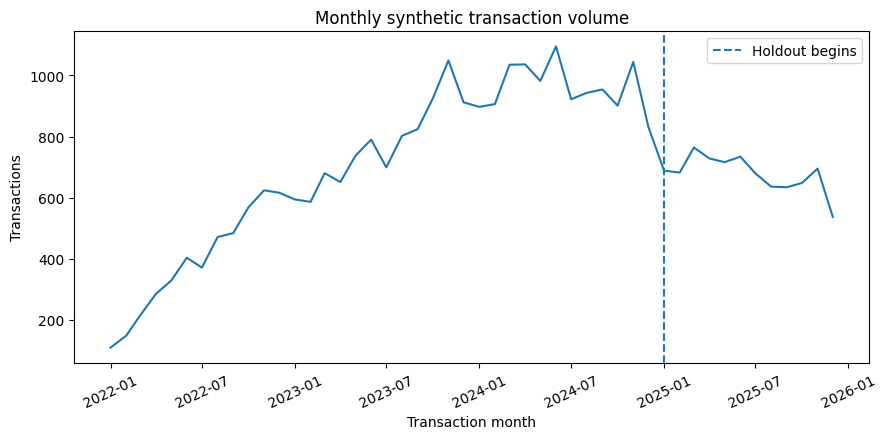

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
monthly = transactions.groupby(transactions.transaction_date.dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()
ax.plot(monthly.index, monthly.values)
ax.axvline(HOLDOUT_START, linestyle='--', label='Holdout begins')
ax.set(title='Monthly synthetic transaction volume', ylabel='Transactions', xlabel='Transaction month')
ax.legend(); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

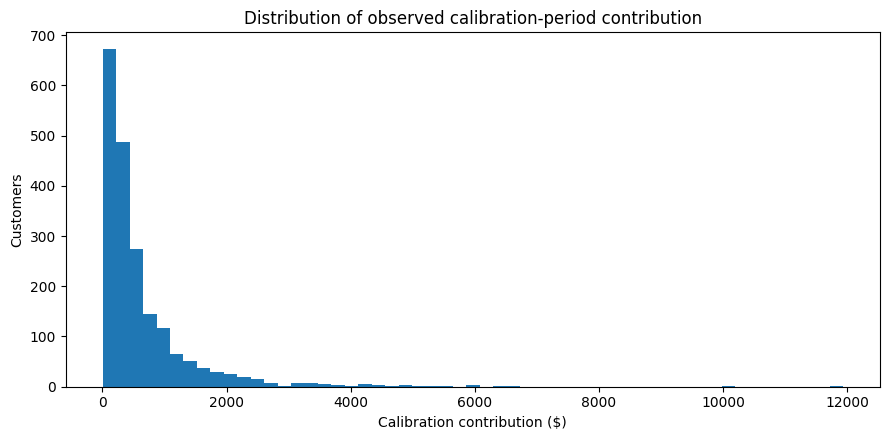

Share with zero holdout transactions: 56.8%


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(summary.calibration_contribution, bins=55)
ax.set(title='Distribution of observed calibration-period contribution',
       xlabel='Calibration contribution ($)', ylabel='Customers')
plt.tight_layout(); plt.show()
print('Share with zero holdout transactions:',
      f"{(summary.realized_holdout_transactions == 0).mean():.1%}")

In [9]:
seg_summary = summary.groupby('segment').agg(
    customers=('customer_id', 'size'),
    mean_calibration_purchases=('calibration_purchases', 'mean'),
    mean_calibration_contribution=('calibration_contribution', 'mean'),
    mean_holdout_contribution=('realized_holdout_contribution', 'mean'),
    share_no_holdout_purchases=('realized_holdout_transactions', lambda x: (x == 0).mean()))
seg_summary.round(2)

,customers,mean_calibration_purchases,mean_calibration_contribution,mean_holdout_contribution,share_no_holdout_purchases
segment,,,,,
Enthusiast,278,31.95,1654.83,636.10,0.39
Occasional,990,5.51,316.29,75.64,0.66
Regular,732,15.14,664.38,214.11,0.51


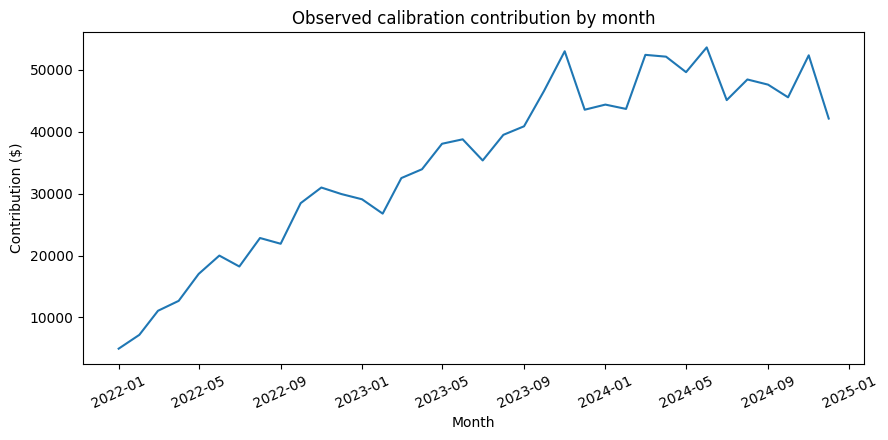

In [10]:
monthly_rev = calibration.assign(month=calibration.transaction_date.dt.to_period('M'))
fig, ax = plt.subplots(figsize=(9, 4.5))
by_month = monthly_rev.groupby('month').contribution.sum()
ax.plot(by_month.index.to_timestamp(), by_month.values)
ax.set(title='Observed calibration contribution by month', ylabel='Contribution ($)', xlabel='Month')
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

## 8. Diagnose purchasing and dropout across the holdout boundary

A decline in 2025 transaction volume is not, by itself, evidence of a code error. Acquisition ends in June 2024, while a portion of the existing customers become inactive over time. We therefore need to separate **observed purchases** (what a real business could see) from **latent dropout** (known only because this dataset is simulated).

The plots below examine monthly purchasing customers, transactions per purchasing customer, and simulated customers still active at the **start** of each month. A customer with no purchases in a month may still be active. The purchase and dropout process is simulated in one continuous loop across 2022–2025; the calendar boundary is used only to label transactions as calibration or holdout, not to change customer behavior.

**Important:** This is a simulated scenario, not evidence that the same patterns hold in real businesses. The ground-truth columns used in these diagnostics must **not** be provided to the predictive models in Notebook 2.

In [ ]:
# Monthly observed activity: one row for every calendar month, including zero-transaction months.
months = pd.period_range(CAL_START.to_period('M'), HOLDOUT_END.to_period('M'), freq='M')
observed = (transactions.assign(month=transactions.transaction_date.dt.to_period('M'))
            .groupby('month').agg(transactions=('transaction_id', 'size'),
                                  purchasing_customers=('customer_id', 'nunique'))
            .reindex(months, fill_value=0))
observed.index.name = 'month'
observed['transactions_per_purchasing_customer'] = (
    observed.transactions.div(observed.purchasing_customers.replace(0, np.nan)))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
observed.purchasing_customers.plot(ax=axes[0], lw=2)
axes[0].set(title='Monthly customers making at least one purchase', ylabel='Purchasing customers')
observed.transactions_per_purchasing_customer.plot(ax=axes[1], lw=2)
axes[1].set(title='Transactions per purchasing customer (not per active customer)',
            ylabel='Transactions / purchaser', xlabel='Month')
for ax in axes:
    ax.axvline(HOLDOUT_START, color='black', ls='--', alpha=0.65, label='Holdout begins')
    ax.grid(axis='y', alpha=0.2)
axes[0].legend()
plt.tight_layout()
plt.show()

print('Mean monthly activity in 2024 vs 2025 (descriptive, not a controlled experiment):')
display(observed.assign(year=observed.index.year).query('year >= 2024')
        .groupby('year')[['transactions', 'purchasing_customers',
                          'transactions_per_purchasing_customer']].mean().round(2))

In [ ]:
# The *latent* active population is known from the simulator, not from transaction records.
# A customer is at risk at the start of month m if acquired by that month and not
# dropped out before m. Dropout occurs at the end of a month in this simulation.
profile_truth = profiles[['customer_id', 'acquisition_date']].merge(
    truth[['customer_id', 'latent_dropout_date']], on='customer_id', validate='one_to_one')
latent_rows = []
for m in months:
    start, end = m.start_time, m.end_time.normalize()
    acquired = profile_truth.acquisition_date.le(end)
    active_during_month = acquired & (profile_truth.latent_dropout_date.isna() |
                                       profile_truth.latent_dropout_date.ge(start))
    dropout_this_month = profile_truth.latent_dropout_date.between(start, end)
    latent_rows.append((m, int(active_during_month.sum()), int(dropout_this_month.sum())))
latent = pd.DataFrame(latent_rows, columns=['month', 'latent_active_customers', 'true_dropouts'])           .set_index('month')
latent['true_monthly_dropout_rate'] = latent.true_dropouts.div(
    latent.latent_active_customers.replace(0, np.nan))
comparison = observed.join(latent)
comparison['purchaser_share_of_latent_active'] = comparison.purchasing_customers.div(
    comparison.latent_active_customers.replace(0, np.nan))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
comparison[['latent_active_customers', 'purchasing_customers']].plot(ax=axes[0], lw=2)
axes[0].set(title='Latent customers active during month vs. observed purchasing customers',
            ylabel='Customer count')
comparison[['true_monthly_dropout_rate', 'purchaser_share_of_latent_active']].plot(
    ax=axes[1], lw=2)
axes[1].set(title='True dropout rate vs. observed monthly purchase participation',
            ylabel='Monthly rate / share', xlabel='Month')
for ax in axes:
    ax.axvline(HOLDOUT_START, color='black', ls='--', alpha=0.65)
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

print('Last three calibration months and first three holdout months:')
display(comparison.loc['2024-10':'2025-03', ['transactions', 'purchasing_customers',
    'transactions_per_purchasing_customer', 'latent_active_customers',
    'true_dropouts', 'true_monthly_dropout_rate']].round(3))

### 8.1 Boundary and rule-consistency checks

The transaction simulator uses **one purchase-rate equation** (customer rate × month-of-year seasonality × early-tenure adjustment × days exposed) and **one monthly dropout equation** for the entire date range. There is no 2025-specific rate or churn adjustment. `transaction.period` is assigned **after** the simulation, solely for the train/holdout split.

These assertions check observable consequences of that design. They cannot statistically prove that both years have identical observed rates, since the mix of customer tenures and surviving customer types changes over time. They do verify that no new customers enter the holdout, no purchases occur after the month of latent dropout, monthly dropout counts match the simulated statuses, and accounting totals reconcile.

In [ ]:
# Validate the generated data and the precise interpretation of latent dropout.
assert (profiles.acquisition_date < HOLDOUT_START).all(), 'Unexpected holdout acquisition.'
assert (comparison.latent_active_customers >= comparison.purchasing_customers).all()
assert (comparison.true_dropouts <= comparison.latent_active_customers).all()
assert int(comparison.true_dropouts.sum()) == truth.latent_dropout_date.notna().sum()
assert (comparison[['transactions', 'purchasing_customers',
                    'latent_active_customers', 'true_dropouts']] >= 0).all().all()
assert int(comparison.transactions.sum()) == len(transactions)

transaction_truth = transactions[['customer_id', 'transaction_date']].merge(
    truth[['customer_id', 'latent_dropout_date']], on='customer_id', validate='many_to_one')
assert (transaction_truth.latent_dropout_date.isna() |
        (transaction_truth.transaction_date <= transaction_truth.latent_dropout_date)).all(),     'Purchase recorded after latent dropout.'

# Acquisition and latent dropout metadata permit an additional sanity check:
# at risk after month end = at risk during month - month-end dropouts + next-month acquisitions.
assert (comparison.loc['2025-01':, 'latent_active_customers'].diff().dropna() <= 0).all(),     'Latent 2025 active population increased despite no new acquisitions.'

print('PASS: No 2025 acquisitions, true dropout consistent with purchases,')
print('      all monthly totals reconcile and no impossible latent activity detected.')
print('DESIGN CHECK: One continuous generator covers both periods;')
print('      period labels are assigned only after transaction generation.')

# Notes for interpretation: the 2024->2025 volume change can arise simply
# because acquisition ended in 2024 and the latent customer base keeps shrinking.
print('2024 average monthly transactions:', round(comparison.loc['2024', 'transactions'].mean(), 1))
print('2025 average monthly transactions:', round(comparison.loc['2025', 'transactions'].mean(), 1))
print('Latent customers active in Jan 2025:', int(comparison.loc['2025-01', 'latent_active_customers']))
print('Latent customers active in Dec 2025:', int(comparison.loc['2025-12', 'latent_active_customers']))

**Interpretation:** The diagnostic separates the shrinking true active customer population from the frequency of observed purchases among those who buy. Because acquisitions stop before 2025 and dropout continues, declining holdout volume is an expected *possible* outcome, not proof of a discontinuity. Look for an unexpected abrupt change in **purchases per purchaser** as well as in **active customer counts**. The latter is a ground-truth diagnostic only.

**Modeling boundary:** Notebook 2 should load `customer_profiles.csv` and `calibration_transactions.csv` for fitting. It may read 2025 transactions only at evaluation time. `simulation_ground_truth.csv` contains both hidden simulation parameters and realized holdout outcomes and should never be used for model features or hyperparameter selection before final evaluation.

## 9. Export datasets for Notebook 2

This exports comma-separated UTF-8 files, plus a simple metadata file recording the simulation settings. The companion notebook should load **customer profiles and calibration transactions for model fitting**, then load holdout data **only during evaluation**. Ground truth must never be used to construct model features.

Running the notebook twice with the same NumPy/Pandas versions and seed should give the same data. Library upgrades may change low-level random generation behavior; for strict reproducibility, archive the exported CSVs and metadata alongside the notebook.

In [11]:
profiles.to_csv(OUTPUT_DIR / 'customer_profiles.csv', index=False)
transactions.to_csv(OUTPUT_DIR / 'transactions.csv', index=False)
calibration.to_csv(OUTPUT_DIR / 'calibration_transactions.csv', index=False)
truth.to_csv(OUTPUT_DIR / 'simulation_ground_truth.csv', index=False)

import json
metadata = {
    'project': 'Predictive CLV notebook 1 - synthetic data',
    'random_seed': SEED, 'n_customers': N_CUSTOMERS,
    'calibration_start': str(CAL_START.date()),
    'calibration_end': str(CAL_END.date()),
    'holdout_start': str(HOLDOUT_START.date()),
    'holdout_end': str(HOLDOUT_END.date()),
    'generator': 'heterogeneous monthly Poisson purchases and latent monthly dropout',
    'training_data': ['customer_profiles.csv', 'calibration_transactions.csv'],
    'evaluation_only': ['simulation_ground_truth.csv', 'holdout rows of transactions.csv'],
    'notes': 'Synthetic educational dataset; not a validated representation of any industry.'
}
(OUTPUT_DIR / 'simulation_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for file in sorted(OUTPUT_DIR.iterdir()):
    print(f'{file.name:34s} {file.stat().st_size / 1024:8.1f} KB')

calibration_transactions.csv         1422.9 KB
customer_profiles.csv                  76.1 KB
simulation_ground_truth.csv           147.5 KB
simulation_metadata.json                0.6 KB
transactions.csv                     1846.8 KB


In [12]:
# Optional in Google Colab: download all CSV files and metadata as one zip.
import shutil
zip_path = shutil.make_archive('clv_synthetic_data', 'zip', root_dir='.', base_dir=str(OUTPUT_DIR))
print('Created:', zip_path)
# In Colab, uncomment the next two lines to download to your computer:
# from google.colab import files
# files.download(zip_path)

Created: /mnt/data/clv_notebook1/clv_synthetic_data.zip


## 10. What comes next?

**Notebook 2** will prepare proper calibration-only recency/frequency/monetary features, establish a baseline, fit a probabilistic purchase model, test the Gamma-Gamma assumptions, and compare those results with selected ML approaches. All models will be evaluated on **2025 holdout transactions** using customer-level errors, aggregate contribution forecasts, and calibration where appropriate.

**Interpretation cautions:**

- This is a **noncontractual** business: lack of purchasing is not an observed cancellation. A naive survival model should not label every nonbuyer as churned.
- A first purchase is included for every acquired customer; standard BG/NBD implementations often count **repeat** purchases *after* the first purchase. The modeling notebook must calculate frequency accordingly.
- Monetary values are positive here by design, but Gamma-Gamma is not automatically appropriate. Its assumptions and the purchase-frequency/value relationship must be inspected.
- The latent dropout dates and realized holdout outcomes are known to us only as simulation authors. They are not legitimate training predictors.
- Simulated experiments offer a controlled teaching example; useful real-world conclusions require external validation using actual data.

*End of Notebook 1.*